# XI-IoTID Ablation 1: CNN + Transformer Only (No BiLSTM)

Removes the **BiLSTM** component from the full CNN→Transformer→BiLSTM pipeline.

- Dataset: X-IIoTID (`X-IIoTID dataset.csv`) | 57 features
- Unseen class: `C&C` | Seen: 8 classes
- CNN: 128→256 channels | Transformer: d_model=256, nhead=4
- Gate uses **64-dim fc1 embeddings** (same as full model)
- Emerging **excluded** from confusion matrix & all metrics

In [1]:
!pip install torch pandas numpy scikit-learn matplotlib seaborn tqdm --quiet

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.preprocessing import StandardScaler, LabelEncoder, RobustScaler
from sklearn.metrics import (confusion_matrix, classification_report,
                              accuracy_score, precision_score, recall_score, f1_score)
from sklearn.neighbors import NearestNeighbors
from tqdm import tqdm

np.random.seed(42)
torch.manual_seed(42)

# ── Device ─────────────────────────────────────────────────
if torch.cuda.is_available():
    try:
        _ = torch.zeros(1).cuda()
        device = torch.device("cuda")
        print(f"GPU: {torch.cuda.get_device_name(0)}")
    except Exception as e:
        print(f"GPU failed ({e}), using CPU.")
        device = torch.device("cpu")
else:
    device = torch.device("cpu")
print(f"Device: {device}")

GPU: Tesla T4
Device: cuda


In [10]:
CONFIG = {
    'batch_size': 512,
    'epochs': 30,
    'learning_rate': 1e-4,
    'input_shape': (57, 1),
    'dataset_path': '/kaggle/input/datasets/munaalhawawreh/xiiotid-iiot-intrusion-dataset/X-IIoTID dataset.csv',
    'val_fraction': 0.15,
}

SEEN_CLASSES   = ['Normal','Exfiltration','Lateral _movement','Tampering',
                  'RDOS','Exploitation','Reconnaissance','Weaponization']
UNSEEN_CLASSES = ['C&C']

CLASS_SPLITS = {
    'Normal':           {'train': 128640, 'test': 32160},
    'Weaponization':    {'train': 18800,  'test': 4700},
    'RDOS':             {'train': 36400,  'test': 9100},
    'Lateral _movement':{'train': 19600,  'test': 4900},
    'Reconnaissance':   {'train': 36400,  'test': 9100},
    'Exfiltration':     {'train': 17200,  'test': 4300},
    'Tampering':        {'train': 3260,   'test': 815},
    'C&C':              {'train': 1960,   'test': 490},
    'Exploitation':     {'train': 804,    'test': 201},
}

print(f"Seen   : {SEEN_CLASSES}")
print(f"Unseen : {UNSEEN_CLASSES}")

Seen   : ['Normal', 'Exfiltration', 'Lateral _movement', 'Tampering', 'RDOS', 'Exploitation', 'Reconnaissance', 'Weaponization']
Unseen : ['C&C']


In [4]:
class IoTDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):        return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

def load_and_process_df(config):
    print("Loading dataset...")
    df = pd.read_csv(config['dataset_path'])
    print(f"Duplicated rows: {df.duplicated().sum()}")

    df = df[df['class2'] != 'crypto-ransomware']
    df.dropna(subset=['class2'], inplace=True)

    cols_to_drop = ['Date','Timestamp','Scr_IP','Des_IP','class1','class3',
                    'missed_bytes','Scr_port','Des_port']
    df.drop(columns=[c for c in cols_to_drop if c in df.columns], inplace=True)

    for col in df.columns:
        if df[col].dtype == 'object' and col != 'class2':
            df[col] = pd.to_numeric(df[col], errors='coerce')
    df.fillna(0, inplace=True)
    return df

def make_seen_unseen_splits(df, seen_classes, splits, label_col='class2',
                             val_fraction=0.15, seed=42, unseen_take_all=True):
    seen_df   = df[df[label_col].isin(seen_classes)].copy()
    unseen_df = df[~df[label_col].isin(seen_classes)].copy()

    train_parts, val_parts, test_seen_parts = [], [], []
    for label in seen_classes:
        c   = splits[label]
        sub = seen_df[seen_df[label_col] == label].sample(frac=1, random_state=seed).reset_index(drop=True)
        train_block = sub.iloc[:c['train']].copy()
        test_block  = sub.iloc[c['train']:c['train']+c['test']].copy()
        n_val = int(round(len(train_block) * val_fraction))
        val_block   = train_block.iloc[:n_val].copy()
        train_block = train_block.iloc[n_val:].copy()
        train_parts.append(train_block)
        val_parts.append(val_block)
        test_seen_parts.append(test_block)

    train_df     = pd.concat(train_parts,     ignore_index=True)
    val_df       = pd.concat(val_parts,       ignore_index=True)
    test_seen_df = pd.concat(test_seen_parts, ignore_index=True)
    test_unseen_df = unseen_df if unseen_take_all else unseen_df.iloc[0:0].copy()
    test_final_df  = pd.concat([test_seen_df, test_unseen_df], ignore_index=True)
    return train_df, val_df, test_seen_df, test_unseen_df, test_final_df

# ── Run data pipeline ─────────────────────────────────────
df = load_and_process_df(CONFIG)
train_df, val_df, test_seen_df, test_unseen_df, test_final_df = make_seen_unseen_splits(
    df, seen_classes=SEEN_CLASSES, splits=CLASS_SPLITS,
    val_fraction=CONFIG['val_fraction'], seed=42, unseen_take_all=True)

print("Train:", train_df['class2'].value_counts().to_dict())
print("Val:  ", val_df['class2'].value_counts().to_dict())
print("Test unseen:", test_unseen_df['class2'].value_counts().to_dict())

# ── LabelEncoder (seen only) ──────────────────────────────
le = LabelEncoder()
y_train = le.fit_transform(train_df['class2'].values)
y_val   = le.transform(val_df['class2'].values)
num_classes = len(le.classes_)

X_train      = train_df.drop(['class2'], axis=1).values
X_val        = val_df.drop(['class2'], axis=1).values
X_test_final = test_final_df.drop(['class2'], axis=1).values
y_test_final_str = test_final_df['class2'].values

# ── RobustScaler + clip (prevents blow-ups) ───────────────
scaler  = RobustScaler()
X_train = np.clip(scaler.fit_transform(X_train), -20, 20)
X_val   = np.clip(scaler.transform(X_val),        -20, 20)
X_test_final = np.clip(scaler.transform(X_test_final), -20, 20)

assert np.isfinite(X_train).all() and np.isfinite(X_val).all()

num_features = X_train.shape[1]
CONFIG['input_shape'] = (num_features, 1)
print(f"\nNum features: {num_features} | Num classes: {num_classes}")

# ── Reshape to (N, F, 1) ──────────────────────────────────
X_train      = X_train.reshape(len(X_train), num_features, 1)
X_val        = X_val.reshape(len(X_val), num_features, 1)
X_test_final = X_test_final.reshape(len(X_test_final), num_features, 1)
y_test_dummy = np.zeros(len(X_test_final), dtype=np.int64)

train_dataset = IoTDataset(X_train, y_train)
val_dataset   = IoTDataset(X_val,   y_val)
test_dataset  = IoTDataset(X_test_final, y_test_dummy)

# ── WeightedRandomSampler ─────────────────────────────────
class_counts      = np.bincount(y_train, minlength=num_classes)
sample_weights    = (1.0 / np.maximum(class_counts, 1))[y_train]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], sampler=sampler,
                          shuffle=False, num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=CONFIG['batch_size'],
                          shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=CONFIG['batch_size'],
                          shuffle=False, num_workers=4, pin_memory=True)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test_final)}")

Loading dataset...


/tmp/ipykernel_57/4064466105.py:10: DtypeWarning: Columns (1,3,5,12,24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(config['dataset_path'])


Duplicated rows: 4260
Train: {'Normal': 109344, 'RDOS': 30940, 'Reconnaissance': 30940, 'Lateral _movement': 16660, 'Weaponization': 15980, 'Exfiltration': 14620, 'Tampering': 2771, 'Exploitation': 683}
Val:   {'Normal': 19296, 'RDOS': 5460, 'Reconnaissance': 5460, 'Lateral _movement': 2940, 'Weaponization': 2820, 'Exfiltration': 2580, 'Tampering': 489, 'Exploitation': 121}
Test unseen: {'C&C': 2863}

Num features: 58 | Num classes: 8
Train: 221938 | Val: 39166 | Test: 68139


In [5]:
def train_model_stable(model, train_loader, val_loader, epochs, lr=1e-4,
                       max_norm=1.0, save_path='best_model.pt', patience=10):
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    def bad(t): return torch.isnan(t).any().item() or torch.isinf(t).any().item()

    best_val_acc, no_improve = -1.0, 0
    history = {'accuracy':[], 'val_accuracy':[], 'loss':[], 'val_loss':[]}

    for epoch in range(1, epochs + 1):
        model.train()
        losses, correct, total, bad_batches = [], 0, 0, 0

        for x, y in tqdm(train_loader, desc=f"Epoch {epoch}/{epochs}", leave=True):
            x, y = x.to(device), y.to(device)
            if bad(x): bad_batches += 1; continue
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            if bad(logits): bad_batches += 1; continue
            loss = criterion(logits, y)
            if bad(loss): bad_batches += 1; continue
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)
            optimizer.step()
            losses.append(loss.item())
            _, pred = torch.max(logits, 1)
            total   += y.size(0)
            correct += (pred == y).sum().item()

        avg_loss  = float(np.mean(losses)) if losses else float('nan')
        epoch_acc = correct / max(total, 1)

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                logits = model(x)
                val_loss    += criterion(logits, y).item()
                _, pred      = torch.max(logits, 1)
                val_total   += y.size(0)
                val_correct += (pred == y).sum().item()

        val_acc      = val_correct / max(val_total, 1)
        val_loss_avg = val_loss / max(len(val_loader), 1)
        history['accuracy'].append(epoch_acc)
        history['loss'].append(avg_loss)
        history['val_accuracy'].append(val_acc)
        history['val_loss'].append(val_loss_avg)

        print(f"Epoch {epoch}: loss={avg_loss:.4f} | acc={epoch_acc:.4f} | "
              f"val_loss={val_loss_avg:.4f} | val_acc={val_acc:.4f} | bad_batches={bad_batches}")

        if (val_acc - best_val_acc) > 1e-4:
            best_val_acc = val_acc
            no_improve   = 0
            torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                        'best_val_acc': best_val_acc}, save_path)
            print(f"  --> Best model saved (val_acc={val_acc:.4f})")
        else:
            no_improve += 1

        if patience and no_improve >= patience:
            print(f"Early stopping at epoch {epoch}. Best val_acc={best_val_acc:.4f}")
            break

    if os.path.exists(save_path):
        ckpt = torch.load(save_path, map_location=device)
        model.load_state_dict(ckpt['model_state_dict'])
        print(f"Restored best model (val_acc={ckpt['best_val_acc']:.4f})")
    return history

def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history['loss'],      label='Train Loss')
    ax1.plot(history['val_loss'],  label='Val Loss')
    ax1.set_title(f'{title} - Loss'); ax1.legend()
    ax2.plot(history['accuracy'],     label='Train Acc')
    ax2.plot(history['val_accuracy'], label='Val Acc')
    ax2.set_title(f'{title} - Accuracy'); ax2.legend()
    plt.tight_layout()
    plt.savefig(f'{title.replace(" ","_")}_training_curves.png', dpi=150)
    plt.show()

In [6]:
# ── MinMax Gate (uses EMBEDDINGS, same as original notebook) ──
class MinMaxThreeWayGate:
    def __init__(self, q=3, dist_percentile=100,
                 inside_conf=0.8, inside_red=1.0, support_elev=1.0):
        self.q = q
        self.dist_percentile = dist_percentile
        self.inside_conf   = inside_conf
        self.inside_red    = inside_red
        self.support_elev  = support_elev

    def fit(self, X_train, y_train):
        self.X_train = np.asarray(X_train, np.float32)
        self.y_train = np.asarray(y_train)
        self.classes_ = np.unique(self.y_train)
        self.class_to_idx_ = {c: i for i, c in enumerate(self.classes_)}
        C = len(self.classes_)

        self.nn_train_ = NearestNeighbors(n_neighbors=self.q+1, metric='euclidean').fit(self.X_train)
        neigh_idx_train = self.nn_train_.kneighbors(self.X_train, return_distance=False)[:, 1:]

        e_train = np.zeros((len(self.X_train), C), np.float32)
        for i in tqdm(range(len(self.X_train)), desc='Gate fit e_train', leave=False):
            for c in self.y_train[neigh_idx_train[i]]:
                e_train[i, self.class_to_idx_[c]] += 1.0
        self.e_train_ = e_train / float(self.q)

        dists_train = self.nn_train_.kneighbors(self.X_train, return_distance=True)[0][:, 1:]
        self.dist_tau_ = np.percentile(dists_train.mean(axis=1), self.dist_percentile)

        self.nn_test_ = NearestNeighbors(n_neighbors=self.q, metric='euclidean').fit(self.X_train)
        return self

    def predict_region(self, X_test):
        X_test = np.asarray(X_test, np.float32)
        C = len(self.classes_)
        dists, neigh_idx = self.nn_test_.kneighbors(X_test, return_distance=True)

        e_test = np.zeros((len(X_test), C), np.float32)
        for i in range(len(X_test)):
            for c in self.y_train[neigh_idx[i]]:
                e_test[i, self.class_to_idx_[c]] += 1.0
        e_test /= float(self.q)

        best_k     = e_test.argmax(axis=1)
        best_class = self.classes_[best_k]
        conf       = e_test[np.arange(len(X_test)), best_k]

        reduction = np.array([self.e_train_[neigh_idx[i]][:, best_k[i]].min()
                               for i in range(len(X_test))], dtype=np.float32)
        elevation = np.array([self.e_train_[neigh_idx[i]][:, best_k[i]].max()
                               for i in range(len(X_test))], dtype=np.float32)

        inside  = (conf >= self.inside_conf) & (reduction >= self.inside_red)
        support = (elevation >= self.support_elev)
        region  = np.where(inside, 'inside', np.where(support, 'partial', 'outside'))
        region  = np.where(dists.mean(axis=1) > self.dist_tau_, 'outside', region)
        return best_class, region, conf

def extract_train_embeddings(model, loader, device):
    """Extract fc1 embeddings from the model for gate fitting."""
    model.eval()
    feats, labels = [], []
    with torch.no_grad():
        for x, y in tqdm(loader, desc='Extract train embeddings'):
            x = x.to(device)
            _, emb = model(x, return_embedding=True)
            feats.append(emb.cpu().numpy())
            labels.append(y.numpy())
    return np.vstack(feats), np.concatenate(labels)

def infer_open_set(model, loader, gate, le, device):
    """Run open-set inference using embeddings + MinMax gate."""
    model.eval()
    preds = []
    with torch.no_grad():
        for x, _ in tqdm(loader, desc='Inference'):
            x = x.to(device)
            _, emb = model(x, return_embedding=True)
            best_idx, region, _ = gate.predict_region(emb.cpu().numpy())
            for k, r in zip(best_idx, region):
                preds.append(le.inverse_transform([k])[0] if r == 'inside' else 'Emerging')
    return np.array(preds)

In [7]:
def evaluate_model(model, test_loader, gate, le, y_test_final_str, model_name):
    print(f"\n{'='*60}")
    print(f"  EVALUATION: {model_name}")
    print(f"{'='*60}")

    y_pred = infer_open_set(model, test_loader, gate, le, device)

    # ── Exclude 'Emerging' from metrics & confusion matrix ──────
    mask     = (np.array(y_pred) != 'Emerging') & (np.array(y_test_final_str) != 'Emerging')
    y_true_f = np.array(y_test_final_str)[mask]
    y_pred_f = np.array(y_pred)[mask]

    print(f"\n  Total test samples  : {len(y_test_final_str)}")
    print(f"  Predicted Emerging  : {int((np.array(y_pred)=='Emerging').sum())} (excluded)")
    print(f"  Evaluated samples   : {int(mask.sum())}")

    all_classes = sorted(list(set(y_true_f) | set(y_pred_f)))

    acc  = accuracy_score(y_true_f, y_pred_f)
    prec = precision_score(y_true_f, y_pred_f, average='weighted', zero_division=0)
    rec  = recall_score(y_true_f, y_pred_f, average='weighted', zero_division=0)
    f1   = f1_score(y_true_f, y_pred_f, average='weighted', zero_division=0)

    print(f"\n  Accuracy : {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}")
    print(f"  F1-Score : {f1:.4f}")
    print("\n  Classification Report (Emerging excluded):")
    print(classification_report(y_true_f, y_pred_f, zero_division=0))

    # Confusion Matrix
    cm = confusion_matrix(y_true_f, y_pred_f, labels=all_classes)
    plt.figure(figsize=(11, 9))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=all_classes, yticklabels=all_classes)
    plt.title(f'Confusion Matrix - {model_name}\n(Emerging excluded)')
    plt.ylabel('True Label'); plt.xlabel('Predicted Label')
    plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(f'{model_name.replace(" ","_")}_confusion_matrix.png', dpi=150)
    plt.show()

    return {'model': model_name, 'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1}

In [8]:
# ============================================================
# ABLATION 1: CNN + Transformer Only  (No BiLSTM)
#
# Full model: CNN(1->128->256) -> PosEnc -> Transformer(d=256)
#             -> BiLSTM(in=256,hid=64,bidir) -> fc1(128->64) -> out
#
# This ablation removes BiLSTM.
# Transformer output (B, SeqLen, 256) is globally averaged -> fc1(256->64) -> out
# NOTE: fc1 input changes from 128 (BiLSTM bidir) to 256 (GAP output)
# return_embedding=True still returns the 64-dim fc1 output for gate compatibility
# ============================================================

class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe  = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32)
                        * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1), :])


class CNNTransformerOnly(nn.Module):
    """
    Ablation: CNN + Transformer, BiLSTM removed.
    Gate uses 64-dim fc1 embeddings (same interface as full model).
    """
    def __init__(self, input_len, num_classes):
        super().__init__()
        # CNN — identical channel sizes to full model
        self.conv1 = nn.Conv1d(1,   128, 3, padding=1)
        self.conv2 = nn.Conv1d(128, 256, 3, padding=1)
        self.relu  = nn.ReLU()
        self.pool  = nn.MaxPool1d(2)

        max_len = max(1, input_len // 2)
        self.pos = SinusoidalPositionalEncoding(256, max_len=max_len, dropout=0.1)

        # Transformer — identical to full model
        enc_layer = nn.TransformerEncoderLayer(d_model=256, nhead=4, dim_feedforward=256,
                                               dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=1)

        # Global Average Pool replaces BiLSTM
        self.gap = nn.AdaptiveAvgPool1d(1)

        # Classifier — fc1 input is 256 (from GAP) instead of 128 (from BiLSTM)
        self.fc1  = nn.Linear(256, 64)
        self.drop = nn.Dropout(0.3)
        self.out  = nn.Linear(64, num_classes)

        for m in self.modules():
            if isinstance(m, (nn.Linear, nn.Conv1d)):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None: nn.init.zeros_(m.bias)

    def forward(self, x, return_embedding=False):
        x = x.permute(0, 2, 1)           # (B,1,F)
        x = self.relu(self.conv1(x))      # (B,128,F)
        x = self.pool(x)                  # (B,128,F/2)
        x = self.relu(self.conv2(x))      # (B,256,F/2)
        x = x.permute(0, 2, 1)           # (B,F/2,256)
        x = self.pos(x)
        x = self.transformer(x)           # (B,F/2,256)
        x = x.permute(0, 2, 1)           # (B,256,F/2)
        x = self.gap(x).squeeze(-1)       # (B,256)
        emb    = self.relu(self.fc1(x))   # (B,64)
        logits = self.out(self.drop(emb))
        return (logits, emb) if return_embedding else logits

INPUT_DIM = CONFIG['input_shape'][0]
model_no_bilstm = CNNTransformerOnly(INPUT_DIM, num_classes).to(device)
total_p = sum(p.numel() for p in model_no_bilstm.parameters() if p.requires_grad)
print(f"CNN+Transformer (No BiLSTM) | Parameters: {total_p:,}")
print(model_no_bilstm)

CNN+Transformer (No BiLSTM) | Parameters: 511,816
CNNTransformerOnly(
  (conv1): Conv1d(1, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (conv2): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (pos): SinusoidalPositionalEncoding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=256, bias=True)
        (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (dr

Training CNN+Transformer (No BiLSTM)...


Epoch 1/30: 100%|██████████| 434/434 [00:12<00:00, 34.08it/s]


Epoch 1: loss=1.0240 | acc=0.7625 | val_loss=0.9527 | val_acc=0.7818 | bad_batches=0
  --> Best model saved (val_acc=0.7818)


Epoch 2/30: 100%|██████████| 434/434 [00:12<00:00, 34.05it/s]


Epoch 2: loss=0.8036 | acc=0.8703 | val_loss=0.7930 | val_acc=0.8758 | bad_batches=0
  --> Best model saved (val_acc=0.8758)


...

Epoch 28: loss=0.5522 | acc=0.9753 | val_loss=0.5836 | val_acc=0.9646 | bad_batches=0
  --> Best model saved (val_acc=0.9646)


Epoch 29/30: 100%|██████████| 434/434 [00:13<00:00, 31.69it/s]


Epoch 29: loss=0.5504 | acc=0.9757 | val_loss=0.5886 | val_acc=0.9553 | bad_batches=0


Epoch 30/30: 100%|██████████| 434/434 [00:13<00:00, 31.74it/s]


Epoch 30: loss=0.5500 | acc=0.9758 | val_loss=0.5799 | val_acc=0.9649 | bad_batches=0
  --> Best model saved (val_acc=0.9649)
Restored best model (val_acc=0.9649)


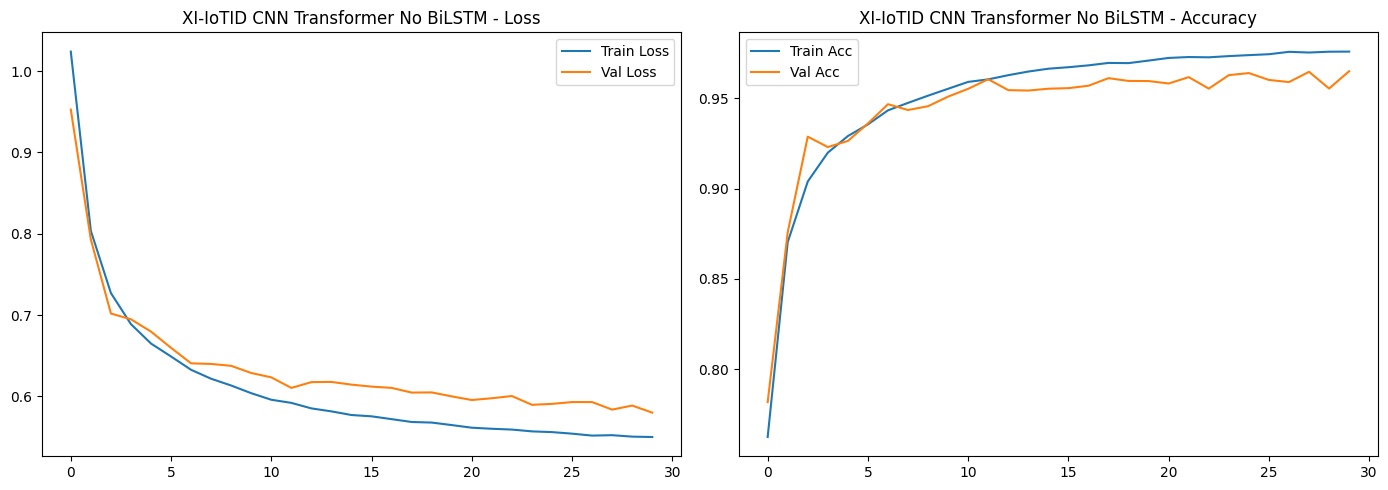

In [11]:
print("Training CNN+Transformer (No BiLSTM)...")
history_nb = train_model_stable(
    model_no_bilstm, train_loader, val_loader,
    epochs=CONFIG['epochs'], lr=CONFIG['learning_rate'],
    save_path='xiiotid_no_bilstm_best.pt', patience=10)
plot_history(history_nb, "XI-IoTID CNN Transformer No BiLSTM")

In [12]:
print("Fitting MinMax Gate for CNN+Transformer (No BiLSTM)...")
train_emb_nb, train_lbl_nb = extract_train_embeddings(model_no_bilstm, train_loader, device)
gate_nb = MinMaxThreeWayGate(q=3, dist_percentile=100,
                              inside_conf=0.8, inside_red=1.0, support_elev=1.0).fit(
    train_emb_nb, train_lbl_nb)
print(f"Gate fitted | emb shape: {train_emb_nb.shape}")

Fitting MinMax Gate for CNN+Transformer (No BiLSTM)...


Extract train embeddings: 100%|██████████| 434/434 [00:04<00:00, 91.81it/s] 


Gate fitted | emb shape: (221938, 64)



  EVALUATION: XI-IoTID CNN + Transformer (No BiLSTM)


Inference: 100%|██████████| 134/134 [01:05<00:00,  2.06it/s]



  Total test samples  : 68139
  Predicted Emerging  : 5830 (excluded)
  Evaluated samples   : 62309

  Accuracy : 0.9488
  Precision: 0.9276
  Recall   : 0.9488
  F1-Score : 0.9366

  Classification Report (Emerging excluded):
                   precision    recall  f1-score   support

              C&C       0.00      0.00      0.00      2438
     Exfiltration       1.00      1.00      1.00      4281
     Exploitation       0.15      0.93      0.25       189
Lateral _movement       0.96      0.99      0.98      4688
           Normal       0.96      0.98      0.97     27608
             RDOS       0.99      1.00      1.00      9094
   Reconnaissance       0.98      0.99      0.98      8555
        Tampering       0.58      0.99      0.73       768
    Weaponization       1.00      1.00      1.00      4688

         accuracy                           0.95     62309
        macro avg       0.73      0.88      0.77     62309
     weighted avg       0.93      0.95      0.94     62309



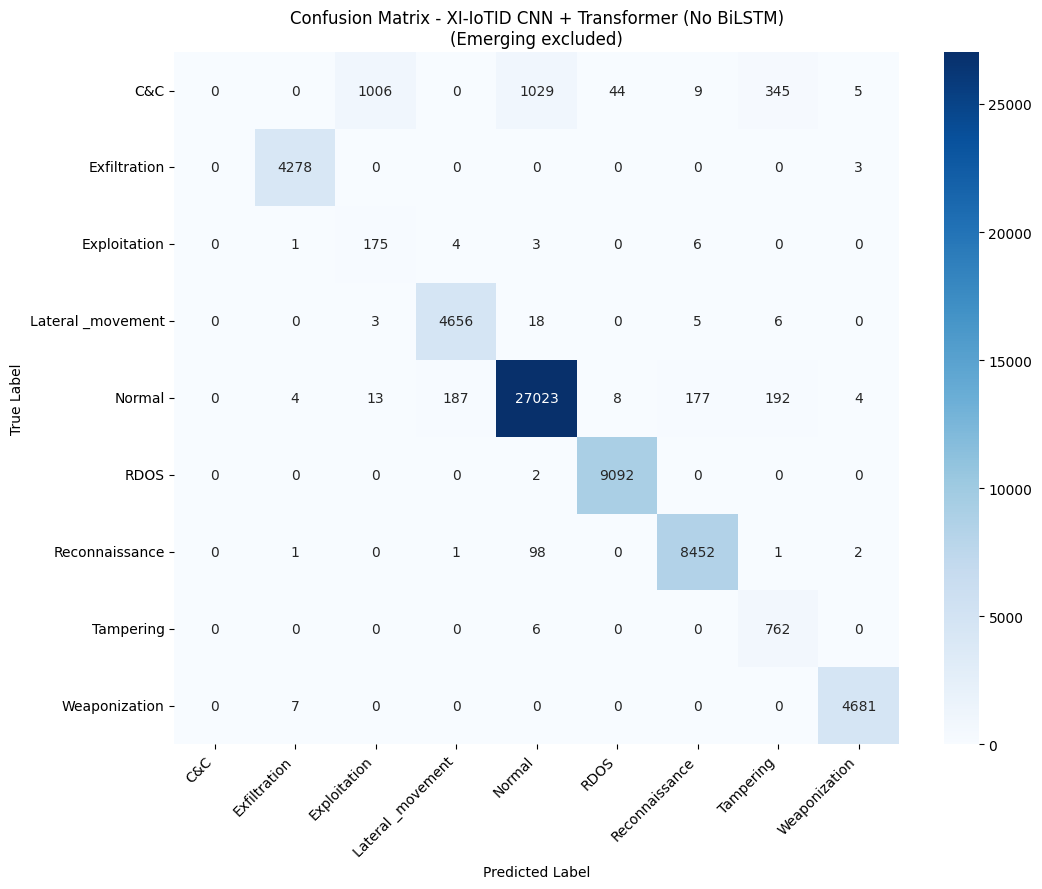

In [13]:
results_nb = evaluate_model(model_no_bilstm, test_loader, gate_nb, le,
                             y_test_final_str, "XI-IoTID CNN + Transformer (No BiLSTM)")